## Part A – Introduction to Random Networks

In [27]:
import networkx as nx
n = 100
p = 0.05

G = nx.erdos_renyi_graph(n, p)

In [28]:
G.number_of_edges()

266

In [29]:
G.degree()

DegreeView({0: 5, 1: 6, 2: 6, 3: 8, 4: 4, 5: 6, 6: 5, 7: 4, 8: 7, 9: 10, 10: 6, 11: 4, 12: 4, 13: 4, 14: 6, 15: 4, 16: 5, 17: 5, 18: 6, 19: 3, 20: 6, 21: 3, 22: 5, 23: 6, 24: 7, 25: 7, 26: 5, 27: 3, 28: 9, 29: 7, 30: 6, 31: 5, 32: 4, 33: 6, 34: 9, 35: 6, 36: 4, 37: 5, 38: 3, 39: 8, 40: 4, 41: 3, 42: 4, 43: 6, 44: 6, 45: 5, 46: 5, 47: 8, 48: 4, 49: 9, 50: 3, 51: 4, 52: 7, 53: 6, 54: 2, 55: 6, 56: 7, 57: 3, 58: 4, 59: 3, 60: 7, 61: 1, 62: 8, 63: 7, 64: 0, 65: 4, 66: 2, 67: 5, 68: 9, 69: 6, 70: 1, 71: 4, 72: 7, 73: 5, 74: 7, 75: 6, 76: 7, 77: 8, 78: 8, 79: 6, 80: 6, 81: 5, 82: 6, 83: 6, 84: 6, 85: 4, 86: 4, 87: 7, 88: 3, 89: 5, 90: 2, 91: 6, 92: 3, 93: 8, 94: 2, 95: 9, 96: 9, 97: 2, 98: 5, 99: 5})

In [30]:
print(f"Average degree: {sum(dict(G.degree()).values()) / n}")

Average degree: 5.32


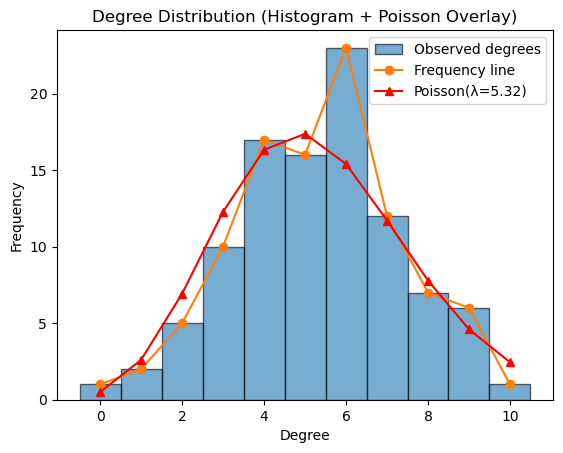

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import poisson
import collections

# --- Degree data ---
degree_dict = dict(G.degree())
degrees = list(degree_dict.values())

# --- Histogram ---
plt.hist(
    degrees,
    bins=[x - 0.5 for x in range(max(degrees) + 2)],
    edgecolor='black',
    alpha=0.6,
    label="Observed degrees"
)

# --- Line plot for observed frequencies ---
counts = collections.Counter(degrees)
x, y = zip(*sorted(counts.items()))
plt.plot(x, y, marker='o', linestyle='-', label="Frequency line")

# --- Poisson overlay ---
N = len(degrees)
lambda_ = np.mean(degrees)

k = np.arange(0, max(degrees) + 1)
pmf = poisson.pmf(k, mu=lambda_)
expected_counts = pmf * N

plt.plot(k, expected_counts, 'r^-', label=f'Poisson(λ={lambda_:.2f})')

# --- Labels ---
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution (Histogram + Poisson Overlay)")
plt.legend()
plt.show()


Yes, the degree distribution resembles a Poisson distribution. In an Erdős–Rényi random network the degree distribution is binomial, but when the network is large and the connection probability is small (so that 
⟨𝑘⟩≪𝑁), the binomial can be approximated by a Poisson distribution with parameter λ=⟨k⟩.
Since this condition holds for our network, we observe a degree distribution close to Poisson. But there are some discrepancies between the degree distribution and the Poisson distribution, probably because n is not large enough.

## Part B – Connectivity & Components

### Connected components

In [32]:
n = 100
p = 0.01
G = nx.erdos_renyi_graph(n, p)

In [33]:
nx.number_connected_components(G)

46

In [34]:
largest_cc = max(nx.connected_components(G), key=len)
len(largest_cc)

19

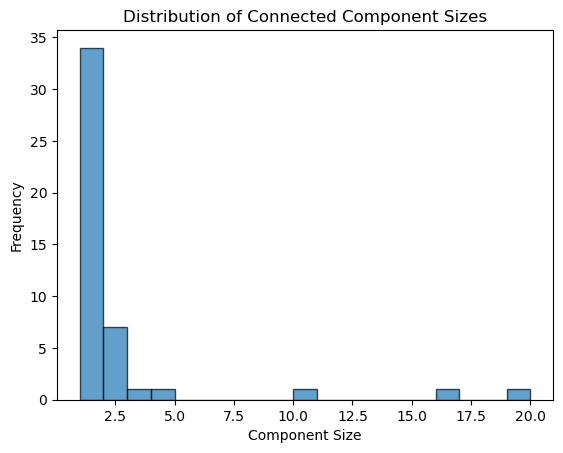

In [35]:
# Distribution of component sizes
component_sizes = [len(c) for c in nx.connected_components(G)]
plt.hist(
    component_sizes,
    bins=range(1, max(component_sizes) + 2),
    edgecolor='black',
    alpha=0.7
)
plt.xlabel("Component Size")
plt.ylabel("Frequency")
plt.title("Distribution of Connected Component Sizes")
plt.show()

### Threshold phenomena

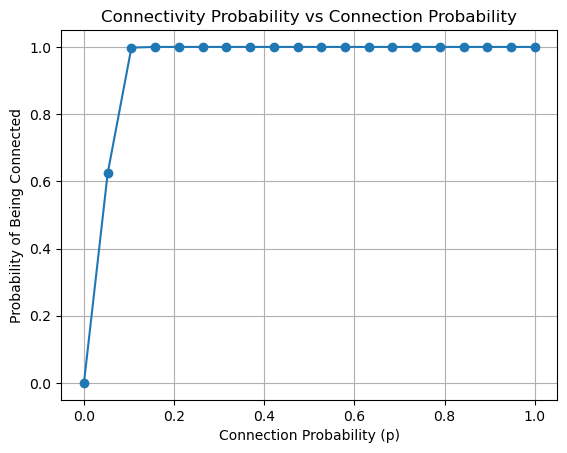

In [39]:
ps = np.linspace(0, 1, 20)
connected_probabilities = []
n = 100
N = 500

for p in ps:
    connected_graphs = 0
    for i in range(N):
        G = nx.erdos_renyi_graph(n, p)
        connected_graphs += int(nx.is_connected(G))
    connected_probabilities.append(connected_graphs / N)

plt.plot(ps, connected_probabilities, marker='o')
plt.xlabel("Connection Probability (p)")
plt.ylabel("Probability of Being Connected")
plt.title("Connectivity Probability vs Connection Probability")
plt.grid()
plt.show()

As we increase p, the graph transitions from a regime with many disconnected components to one where a giant component appears, and finally to a regime where the graph is almost surely connected. For n = 100, this connectivity transition happens around p ≈ log(100) / 100 ≈ 0.046. Our experiments show that by p = 0.1, the graph is connected with very high probability, so we can say it is “almost surely” connected.

## Part C – Clustering & Path Length

### Clustering Coefficient

In [ ]:
n = 200
p = 0.05
average_degree = int(p * n)
beta = 0.

G1 = nx.erdos_renyi_graph(n, p)
G2 = nx.watts_strogatz_graph(n, average_degree, beta)

In [43]:
cc_er = nx.average_clustering(G1)
cc_ws = nx.average_clustering(G2)
print(f"Average Clustering Coefficient (Erdős-Rényi): {cc_er:.4f}")
print(f"Average Clustering Coefficient (Watts-Strogatz): {cc_ws:.4f}")

Average Clustering Coefficient (Erdős-Rényi): 0.0505
Average Clustering Coefficient (Watts-Strogatz): 0.5254


The average clustering coefficient is 10 times higher in the Watts-Strogatz, which is expected because random graphs don't get hubs and almost all of the nodes have a similar degree, whereas the Watts-Strogatzs model has hubs and therefore exhibits a higher clustering coefficient.

### Average Path Length

In [45]:
av_er = nx.average_shortest_path_length(G1)
av_ws = nx.average_shortest_path_length(G2)
print(f"Average Path Length (Erdős-Rényi): {av_er:.4f}")
print(f"Average Path Length (Watts-Strogatz): {av_ws:.4f}")

Average Path Length (Erdős-Rényi): 2.5681
Average Path Length (Watts-Strogatz): 3.3409


For the Erdős–Rényi random graph G(200, 0.05), the average path length is approximately 2.57, while for the Watts–Strogatz small-world network with the same number of nodes and similar average degree, the average path length is about 3.34. This shows that the Erdős–Rényi graph has slightly shorter paths on average, which is typical for a purely random graph. However, the Watts–Strogatz network still has relatively short path lengths (on the order of log n), so it remains in the “small-world” regime, but with the advantage of much higher clustering compared to the Erdős–Rényi graph.

## Part D – Scaling & Degree Distributions

### Degree Distribution Scaling

In [ ]:
n = 1000
p = 0.01
G = nx.erdos_renyi_graph(n, p)

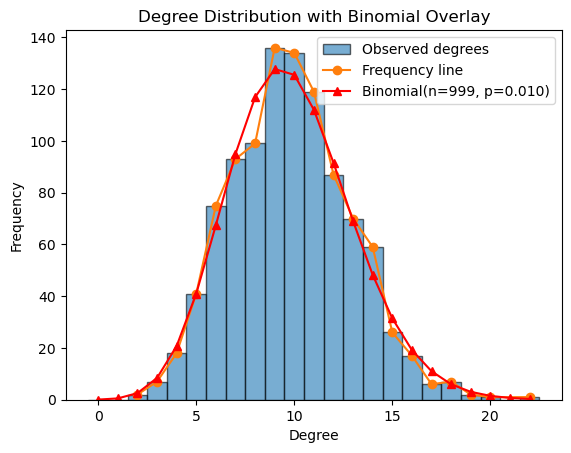

In [51]:
from scipy.stats import binom
# --- Degree data ---
degree_dict = dict(G.degree())
degrees = list(degree_dict.values())

# Infer n and p
n = len(G.nodes())
mean_k = np.mean(degrees)
p = mean_k / (n - 1)

# --- Histogram ---
plt.hist(
    degrees,
    bins=[x - 0.5 for x in range(max(degrees) + 2)],
    edgecolor='black',
    alpha=0.6,
    label="Observed degrees"
)

# --- Line plot for observed frequencies ---
counts = collections.Counter(degrees)
x, y = zip(*sorted(counts.items()))
plt.plot(x, y, marker='o', linestyle='-', label="Frequency line")

# --- Binomial overlay ---
k = np.arange(0, max(degrees) + 1)
pmf = binom.pmf(k, n - 1, p)
expected_counts = pmf * n  # n = number of nodes

plt.plot(k, expected_counts, 'r^-', label=f'Binomial(n={n-1}, p={p:.3f})')

# --- Labels ---
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution with Binomial Overlay")
plt.legend()
plt.show()


In a random graph the degree distribution follows a binomial distribution, but this can be approxiamted when n is large and p is small to a Poisson distibution, with λ=(n−1)p

### Power-law vs Random Networks

In [53]:
n = 1000
m = 3
G_ba = nx.barabasi_albert_graph(n, m)
G_er = nx.erdos_renyi_graph(n, m / (n - 1))

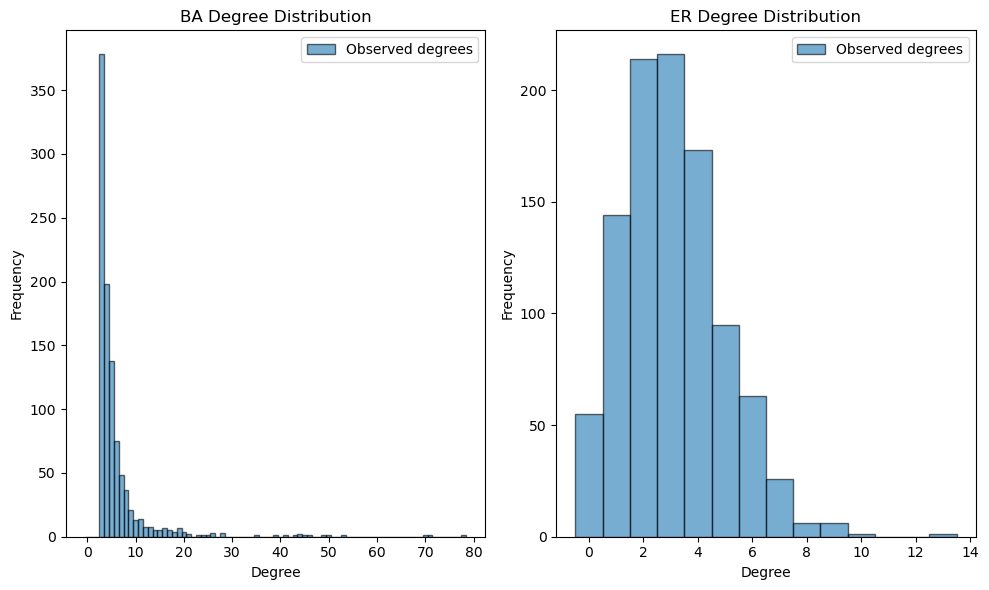

In [55]:
from scipy.stats import binom
# --- Degree data ---
degree_dict = dict(G_ba.degree())
degrees = list(degree_dict.values())

# --- BA Histogram ---
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
axs[0].hist(
    degrees,
    bins=[x - 0.5 for x in range(max(degrees) + 2)],
    edgecolor='black',
    alpha=0.6,
    label="Observed degrees"
)   

# --- ER Histogram ---  
degree_dict_er = dict(G_er.degree())
degrees_er = list(degree_dict_er.values())      
axs[1].hist(
    degrees_er,
    bins=[x - 0.5 for x in range(max(degrees_er) + 2)],
    edgecolor='black',
    alpha=0.6,
    label="Observed degrees"
)


# --- Labels ---
axs[0].set_xlabel("Degree")
axs[0].set_ylabel("Frequency")
axs[0].set_title("BA Degree Distribution")
axs[0].legend()
axs[1].set_xlabel("Degree")
axs[1].set_ylabel("Frequency")
axs[1].set_title("ER Degree Distribution")
axs[1].legend()
plt.tight_layout()
plt.show()


The BA model has a few nodes with a very high degree (80), which are the hubs aro9und which the clusters will form, whereas the ER model's nodes all have around the same average degree, [0,8]. There are no nodes with very high degree and no hubs. Additionally, the degree distribution in BA approximates a power law distribution and the ER distribution approximates a Poisson distribution (the tail in the BA distribution is a lot longer).